# C3 Vision-Semantic Oracle: Held-Out Test Evaluation
Interactive verification notebook for evaluating Qwen2-VL LoRA weights on the held-out test split.

In [2]:
import sys
import json
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Ensure local-vision-oracle package is in path
sys.path.insert(0, str(Path('../local-vision-oracle').resolve()))

from local_vision_oracle.evaluate_test_split import (
    find_default_weights_dir,
    find_default_dataset_path,
    find_default_base_model,
    TestDatasetLoader,
    run_evaluation,
)

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Auto-Detect Paths
Auto-detects fine-tuned LoRA weights in Downloads, base model, and dataset archive.

In [3]:
weights_path = find_default_weights_dir()
dataset_path = find_default_dataset_path()
base_model = find_default_base_model()

print(f'LoRA Weights : {weights_path}')
print(f'Dataset Split: {dataset_path}')
print(f'Base Model   : {base_model}')

LoRA Weights : C:\Users\hp\Downloads\Downloads\c3_lora_run3_weights
Dataset Split: D:\university\Resesarch\colab_c3_dataset.zip
Base Model   : D:\university\Resesarch\RD\models\Qwen2-VL-2B-Instruct


## 2. Inspect Sample Test Screen & Ground Truth

Total test samples in split: 600
Ground Truth:
{
  "has_defect": true,
  "defect_type": "component_overlap",
  "confidence": 1.0,
  "bounding_box": [
    146,
    787,
    213,
    1000
  ],
  "affected_element_id": "AppCompatTextView",
  "explanation": "Component overlap defect: widget AppCompatTextView occludes AppCompatTextView (AppCompatTextView)."
}


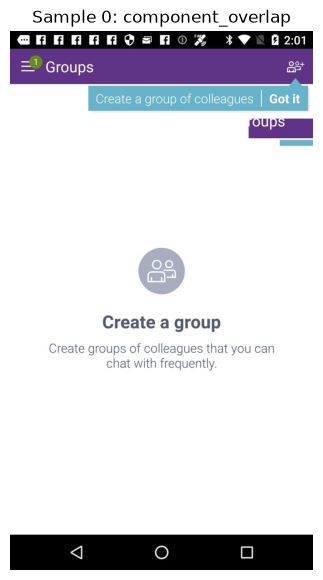

In [4]:
loader = TestDatasetLoader(str(dataset_path))
print(f'Total test samples in split: {len(loader)}')

sample, img = loader.get_sample(0)
gt = json.loads(sample['messages'][1]['content'])
print('Ground Truth:')
print(json.dumps(gt, indent=2))

plt.figure(figsize=(4, 7))
plt.imshow(img)
plt.axis('off')
plt.title(f'Sample 0: {gt.get("defect_type", "clean")}')
plt.show()

## 3. Run Test Evaluation
Run smoke evaluation (e.g. limit=10 for quick smoke test, or limit=None for full test split).

In [6]:
summary = run_evaluation(
    weights_path=str(weights_path),
    dataset_path=str(dataset_path),
    base_model_path=base_model,
    # limit=10,
    load_in_4bit=True,
    output_dir='../results/c3_eval_notebook'
)

 C3 ORACLE: EMPIRICAL TEST SPLIT EVALUATOR
[LoRA Weights]   : C:\Users\hp\Downloads\Downloads\c3_lora_run3_weights
[Dataset Split]  : D:\university\Resesarch\colab_c3_dataset.zip
[Base Model]     : D:\university\Resesarch\RD\models\Qwen2-VL-2B-Instruct
[Output Folder]  : ..\results\c3_eval_notebook
[4-bit NF4]      : True
[Dataset] Loaded 600 total test items. Evaluating: 600

[Model] Loading base model and tokenizer...


Loading weights: 100%|██████████| 729/729 [00:10<00:00, 66.99it/s] 


[Model] Attaching LoRA adapter from C:\Users\hp\Downloads\Downloads\c3_lora_run3_weights...
[Model] Inference ready on cuda:0
[Resume] Resuming from sample 11/600...
[ 20/600] Acc: 75.00% | F1: 66.67% | P: 100.00% | R: 50.00% | Lat: 19248.9ms
[ 30/600] Acc: 76.67% | F1: 69.57% | P: 100.00% | R: 53.33% | Lat: 20719.0ms
[ 40/600] Acc: 80.00% | F1: 69.23% | P: 100.00% | R: 52.94% | Lat: 21476.3ms
[ 50/600] Acc: 78.00% | F1: 64.52% | P: 90.91% | R: 50.00% | Lat: 22107.7ms
[ 60/600] Acc: 76.67% | F1: 65.00% | P: 86.67% | R: 52.00% | Lat: 24962.0ms
[ 70/600] Acc: 72.86% | F1: 61.22% | P: 83.33% | R: 48.39% | Lat: 25529.3ms
[ 80/600] Acc: 72.50% | F1: 62.07% | P: 81.82% | R: 50.00% | Lat: 25437.4ms
[ 90/600] Acc: 70.00% | F1: 59.70% | P: 71.43% | R: 51.28% | Lat: 25845.9ms
[100/600] Acc: 73.00% | F1: 63.01% | P: 74.19% | R: 54.76% | Lat: 25506.5ms
[110/600] Acc: 69.09% | F1: 58.54% | P: 72.73% | R: 48.98% | Lat: 26378.3ms
[120/600] Acc: 67.50% | F1: 56.18% | P: 71.43% | R: 46.30% | Lat: 27223

## 4. Summary Metrics Display

In [ ]:
print('Evaluation Summary Metrics:')
for k, v in summary['metrics'].items():
    print(f'  {k}: {v}')

In [ ]:
## 5. Evaluate weights with rico+teacher trained owleye dataset

In [8]:
import os, sys, gc, torch
from pathlib import Path

# 1. Memory guard for 4GB GPU
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2. Add local package to path
REPO_ROOT = Path(r"D:\university\Resesarch")
sys.path.insert(0, str(REPO_ROOT / "local-vision-oracle"))

from local_vision_oracle.evaluate_test_split import run_evaluation

# 3. Paths
WEIGHTS_PATH = r"C:\Users\hp\Downloads\Downloads\c3_lora_run4_fp16_weights\kaggle\working\qwen2vl_fp16_lora_run4"
DATASET_PATH = r"D:\university\Resesarch\dataset\test.json"
OUTPUT_DIR   = r"D:\university\Resesarch\results\c3_run4_eval"

# 4. Run evaluation (limit=20 first to check speed & memory)
summary = run_evaluation(
    weights_path=WEIGHTS_PATH,
    dataset_path=DATASET_PATH,
    output_dir=OUTPUT_DIR,
    limit=None,            # 20 samples first. Change to None for full test split
    load_in_4bit=True,   # Mandatory for 4GB VRAM
    resume=False
)

 C3 ORACLE: EMPIRICAL TEST SPLIT EVALUATOR
[LoRA Weights]   : C:\Users\hp\Downloads\Downloads\c3_lora_run4_fp16_weights\kaggle\working\qwen2vl_fp16_lora_run4
[Dataset Split]  : D:\university\Resesarch\dataset\test.json
[Base Model]     : D:\university\Resesarch\RD\models\Qwen2-VL-2B-Instruct
[Output Folder]  : D:\university\Resesarch\results\c3_run4_eval
[4-bit NF4]      : True
[Dataset] Loaded 600 total test items. Evaluating: 600

[Model] Loading base model and tokenizer...


Loading weights: 100%|██████████| 729/729 [00:22<00:00, 32.78it/s]


[Model] Attaching LoRA adapter from C:\Users\hp\Downloads\Downloads\c3_lora_run4_fp16_weights\kaggle\working\qwen2vl_fp16_lora_run4...
[Model] Inference ready on cuda:0
[ 10/600] Acc: 60.00% | F1: 60.00% | P: 75.00% | R: 50.00% | Lat: 46056.5ms
[ 20/600] Acc: 65.00% | F1: 53.33% | P: 80.00% | R: 40.00% | Lat: 35430.2ms
[ 30/600] Acc: 63.33% | F1: 47.62% | P: 83.33% | R: 33.33% | Lat: 32528.4ms
[ 40/600] Acc: 70.00% | F1: 50.00% | P: 85.71% | R: 35.29% | Lat: 30083.6ms
[ 50/600] Acc: 72.00% | F1: 53.33% | P: 80.00% | R: 40.00% | Lat: 31411.5ms
[ 60/600] Acc: 68.33% | F1: 45.71% | P: 80.00% | R: 32.00% | Lat: 28656.4ms
[ 70/600] Acc: 65.71% | F1: 42.86% | P: 81.82% | R: 29.03% | Lat: 26054.1ms
[ 80/600] Acc: 66.25% | F1: 44.90% | P: 84.62% | R: 30.56% | Lat: 26301.1ms
[ 90/600] Acc: 68.89% | F1: 48.15% | P: 86.67% | R: 33.33% | Lat: 27545.1ms
[100/600] Acc: 70.00% | F1: 48.28% | P: 87.50% | R: 33.33% | Lat: 27998.2ms
[110/600] Acc: 68.18% | F1: 47.76% | P: 88.89% | R: 32.65% | Lat: 26880